In [1]:
# ── 1. Imports ────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

print("Libraries loaded ✓")
print(f"  pandas  {pd.__version__}")
print(f"  numpy   {np.__version__}")


Libraries loaded ✓
  pandas  2.2.3
  numpy   2.1.3


## 1 · Load & Inspect Dataset

In [2]:
# ── 2. Load Dataset ───────────────────────────────────────────────────────────
DATA_PATH   = "../data/processed/final_training_dataset.csv"   # update path if needed
OUTPUT_PATH = "../data/processed/final_feature_engineered_dataset.csv"

df = pd.read_csv(DATA_PATH)

# ── Auto-detect timestamp column (first datetime-like column) ─────────────────
ts_candidates = [c for c in df.columns if "time" in c.lower() or "date" in c.lower() or "stamp" in c.lower()]
TIMESTAMP_COL = ts_candidates[0] if ts_candidates else df.columns[0]
print(f"Detected timestamp column : '{TIMESTAMP_COL}'")

# ── Auto-detect target column (first energy-like column) ─────────────────────
target_candidates = [c for c in df.columns if "energy" in c.lower() or "kwh" in c.lower() or "power" in c.lower() or "load" in c.lower()]
TARGET_COL = target_candidates[0] if target_candidates else df.columns[1]
print(f"Detected target column    : '{TARGET_COL}'")

# ── Parse & index ─────────────────────────────────────────────────────────────
df[TIMESTAMP_COL] = pd.to_datetime(df[TIMESTAMP_COL])
df = df.set_index(TIMESTAMP_COL).sort_index()

print(f"\nDataset shape : {df.shape}")
print(f"Date range    : {df.index.min()}  →  {df.index.max()}")
print(f"Freq inferred : {pd.infer_freq(df.index)}")
print(f"\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0] if df.isnull().sum().sum() else "  None ✓")
df.head(3)


Detected timestamp column : 'timestamp'
Detected target column    : 'energy_kwh.1'

Dataset shape : (2136, 22)
Date range    : 2025-09-20 05:00:00  →  2026-02-26 12:00:00
Freq inferred : None

Missing values per column:
speed_hi    7
dtype: int64


,energy_kwh.1,temp_hi,bar,dew_in,temp_in,pt_dew,index_thsw,index_uv,hum_out,dose_uv,dd_heat,temp_low,density_in_air,rain,run_wind,emc_in,rate_rain,out_temp,speed_hi,speed_wind,tx_wind,hum_in
timestamp,,,,,,,,,,,,,,,,,,,,,,
2025-09-20 05:00:00,276.5000,30.3750,29.8315,17.6250,23.7750,26.5500,44.7750,4.3250,80.5000,0.4625,0.0000,30.1000,0.0726,0.0000,1.6100,12.6500,0.0000,30.2750,17.3000,6.4250,1.0000,68.5000
2025-09-20 06:00:00,269.2500,30.8000,29.8005,21.4000,25.6750,25.9750,43.6250,3.7000,76.0000,0.3975,0.0000,30.6750,0.0716,0.0000,2.7175,15.0350,0.0000,30.7000,19.3000,10.9000,1.0000,77.2500
2025-09-20 07:00:00,286.7500,30.9750,29.7730,22.3750,26.6000,26.0250,42.6000,2.6500,75.2500,0.2825,0.0000,30.8750,0.0712,0.0000,2.6125,15.1750,0.0000,30.9000,17.7000,10.5000,1.0000,77.7500


In [3]:
# Dataset overview
print("=== Dataset Info ===")
df.info()
print("\n=== Descriptive Statistics ===")
df.describe().T


=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2136 entries, 2025-09-20 05:00:00 to 2026-02-26 12:00:00
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   energy_kwh.1    2136 non-null   float64
 1   temp_hi         2136 non-null   float64
 2   bar             2136 non-null   float64
 3   dew_in          2136 non-null   float64
 4   temp_in         2136 non-null   float64
 5   pt_dew          2136 non-null   float64
 6   index_thsw      2136 non-null   float64
 7   index_uv        2136 non-null   float64
 8   hum_out         2136 non-null   float64
 9   dose_uv         2136 non-null   float64
 10  dd_heat         2136 non-null   float64
 11  temp_low        2136 non-null   float64
 12  density_in_air  2136 non-null   float64
 13  rain            2136 non-null   float64
 14  run_wind        2136 non-null   float64
 15  emc_in          2136 non-null   float64
 16  rate_rain       2136 

,count,mean,std,min,25%,50%,75%,max
energy_kwh.1,2136.0000,155.8520,70.5624,10.5000,102.5000,147.7500,201.0625,397.5000
temp_hi,2136.0000,40.3378,7.3370,23.6000,39.1700,42.7575,45.8900,51.2200
bar,2136.0000,29.9559,0.1054,29.6382,29.8800,29.9750,30.0400,30.1750
dew_in,2136.0000,21.8978,1.8787,14.5750,20.6000,22.0750,23.3000,26.8250
temp_in,2136.0000,40.6107,8.0083,22.1250,42.6669,44.5000,45.5581,48.7900
pt_dew,2136.0000,22.6133,2.1962,17.2000,21.1000,22.8000,24.3250,28.2000
index_thsw,2136.0000,30.6381,5.2901,22.0000,27.0000,29.6250,32.8500,54.0500
index_uv,2136.0000,0.8140,1.3742,0.0000,0.0000,0.0000,1.2750,6.9250
hum_out,2136.0000,83.3624,8.5880,54.0000,77.2500,85.0000,89.5000,98.0000
dose_uv,2136.0000,0.6190,1.1926,0.0000,0.0000,0.0000,0.5006,5.9000


### 2.1 · Time-Based Features

In [4]:
# ── 3. Time-Based Features ────────────────────────────────────────────────────
# Capture cyclical patterns inherent in hourly energy data

df["hour"]        = df.index.hour
df["day_of_week"] = df.index.dayofweek          # 0 = Monday
df["month"]       = df.index.month
df["day_of_year"] = df.index.dayofyear
df["is_weekend"]  = (df.index.dayofweek >= 5).astype(int)

# ── Cyclical encoding (sin/cos) avoids the discontinuity at midnight/Jan ──────
df["hour_sin"]        = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"]        = np.cos(2 * np.pi * df["hour"] / 24)
df["month_sin"]       = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"]       = np.cos(2 * np.pi * df["month"] / 12)
df["day_of_week_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["day_of_week_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

print("Time-based features added:")
time_cols = ["hour", "day_of_week", "month", "day_of_year", "is_weekend",
             "hour_sin", "hour_cos", "month_sin", "month_cos",
             "day_of_week_sin", "day_of_week_cos"]
print(df[time_cols].head(3))


Time-based features added:
                     hour  day_of_week  month  day_of_year  is_weekend  \
timestamp                                                                
2025-09-20 05:00:00     5            5      9          263           1   
2025-09-20 06:00:00     6            5      9          263           1   
2025-09-20 07:00:00     7            5      9          263           1   

                     hour_sin  hour_cos  month_sin  month_cos  \
timestamp                                                       
2025-09-20 05:00:00    0.9659    0.2588    -1.0000    -0.0000   
2025-09-20 06:00:00    1.0000    0.0000    -1.0000    -0.0000   
2025-09-20 07:00:00    0.9659   -0.2588    -1.0000    -0.0000   

                     day_of_week_sin  day_of_week_cos  
timestamp                                              
2025-09-20 05:00:00          -0.9749          -0.2225  
2025-09-20 06:00:00          -0.9749          -0.2225  
2025-09-20 07:00:00          -0.9749          -0.222

### 2.2 · Lag Features

In [5]:
# ── 4. Lag Features ───────────────────────────────────────────────────────────
# Directly supply the model with historical target values.
# lag_24 / lag_48 capture daily seasonality (critical for LSTM).
# NOTE: lags are on the TARGET only → no data leakage.

LAG_PERIODS = [1, 2, 3, 24, 48]
for lag in LAG_PERIODS:
    df[f"lag_{lag}"] = df[TARGET_COL].shift(lag)

print("Lag features added:")
lag_cols = [f"lag_{l}" for l in LAG_PERIODS]
print(df[lag_cols].head(50).tail(5))  # show first non-NaN rows


Lag features added:
                       lag_1    lag_2    lag_3   lag_24   lag_48
timestamp                                                       
2025-09-22 10:00:00 271.0000 272.0000 317.7500 121.2500      NaN
2025-09-22 11:00:00 191.5000 271.0000 272.0000 129.5000      NaN
2025-09-22 12:00:00 334.5000 191.5000 271.0000 144.2500      NaN
2025-09-22 18:00:00 272.7500 334.5000 191.5000 148.0000 276.5000
2025-09-22 19:00:00 290.5000 272.7500 334.5000 183.2500 269.2500


### 2.3 · Rolling Window Features

In [6]:
# ── 5. Rolling Window Features ────────────────────────────────────────────────
# Capture short-term and medium-term trends in energy consumption.
# min_periods ensures partial windows still produce values at series start.

WINDOWS = [6, 12, 24]
for w in WINDOWS:
    df[f"rolling_mean_{w}"] = (
        df[TARGET_COL].shift(1)          # shift(1) avoids look-ahead leakage
                      .rolling(window=w, min_periods=max(1, w // 2))
                      .mean()
    )
    df[f"rolling_std_{w}"] = (
        df[TARGET_COL].shift(1)
                      .rolling(window=w, min_periods=max(1, w // 2))
                      .std()
    )

# Exponential weighted mean — captures recent trend with smooth decay
df["ewm_alpha_02"] = df[TARGET_COL].shift(1).ewm(alpha=0.2, adjust=False).mean()
df["ewm_alpha_05"] = df[TARGET_COL].shift(1).ewm(alpha=0.5, adjust=False).mean()

print("Rolling window features added:")
roll_cols = [f"rolling_mean_{w}" for w in WINDOWS] + [f"rolling_std_{w}" for w in WINDOWS]
print(df[roll_cols + ["ewm_alpha_02", "ewm_alpha_05"]].dropna().head(3))


Rolling window features added:
                     rolling_mean_6  rolling_mean_12  rolling_mean_24  \
timestamp                                                               
2025-09-20 17:00:00        209.5833         232.4375         232.4375   
2025-09-20 18:00:00        201.5000         223.9375         227.9808   
2025-09-20 19:00:00        189.9167         214.8750         223.1607   

                     rolling_std_6  rolling_std_12  rolling_std_24  \
timestamp                                                            
2025-09-20 17:00:00        19.1590         42.0127         42.0127   
2025-09-20 18:00:00        22.3344         42.6018         43.3150   
2025-09-20 19:00:00        22.6178         43.6406         45.3556   

                     ewm_alpha_02  ewm_alpha_05  
timestamp                                        
2025-09-20 17:00:00      219.3969      199.9401  
2025-09-20 18:00:00      210.4175      187.2200  
2025-09-20 19:00:00      200.4340      173.8600  


### 2.4 · Interaction & Derived Weather Features

In [7]:
# ── 6. Interaction / Derived Features ────────────────────────────────────────
# Auto-detect temperature, humidity columns (robust to column renaming)

temp_col  = next((c for c in df.columns if c in ("out_temp", "temp_hi", "temp_low", "temp_in")), None)
hum_col   = next((c for c in df.columns if "hum" in c.lower()), None)
wind_col  = next((c for c in df.columns if "speed_wind" in c.lower() or c == "speed_wind"), None)

print(f"Using  temp={temp_col} | humidity={hum_col} | wind={wind_col}")

if temp_col and hum_col:
    # Temperature × Humidity index (thermal comfort proxy)
    df["temp_x_hum"] = df[temp_col] * df[hum_col]

    # Heat Index approximation (Rothfusz equation, °C inputs)
    T = df[temp_col]
    H = df[hum_col]
    df["heat_index_approx"] = (
        -8.78469475556
        + 1.61139411   * T
        + 2.33854883889 * H
        - 0.14611605   * T * H
        - 0.012308094  * T**2
        - 0.016424828  * H**2
        + 0.002211732  * T**2 * H
        + 0.00072546   * T * H**2
        - 0.000003582  * T**2 * H**2
    )

if temp_col and wind_col:
    # Wind Chill approximation (valid for T ≤ 10°C and wind ≥ 4.8 km/h)
    T = df[temp_col]
    W = df[wind_col]
    df["wind_chill_approx"] = (
        13.12 + 0.6215 * T
        - 11.37 * W**0.16
        + 0.3965 * T * W**0.16
    )

# Rain indicator flag
if "rain" in df.columns:
    df["is_raining"] = (df["rain"] > 0).astype(int)

# UV load (daytime energy demand proxy)
if "index_uv" in df.columns:
    df["uv_load"] = df["index_uv"] * df["hour_sin"].clip(lower=0)

print("\nInteraction features:")
interact_cols = [c for c in ["temp_x_hum", "heat_index_approx", "wind_chill_approx",
                              "is_raining", "uv_load"] if c in df.columns]
print(df[interact_cols].describe().T)


Using  temp=temp_hi | humidity=hum_out | wind=speed_wind

Interaction features:
                      count      mean      std       min       25%       50%  \
temp_x_hum        2136.0000 3344.0142 618.3650 2006.2687 2944.7700 3541.3469   
heat_index_approx 2136.0000   95.0637  37.6646   22.1349   82.2696  108.0556   
wind_chill_approx 2136.0000   43.4306   8.1161   24.8195   38.2224   45.9240   
is_raining        2136.0000    0.1344   0.3411    0.0000    0.0000    0.0000   
uv_load           2136.0000    0.7232   1.3040    0.0000    0.0000    0.0000   

                        75%       max  
temp_x_hum        3812.1900 4282.6400  
heat_index_approx  121.3986  167.2566  
wind_chill_approx   49.8007   56.8596  
is_raining           0.0000    1.0000  
uv_load              0.9192    6.9250  


In [8]:
# ── 7. Handle Missing Values ─────────────────────────────────────────────────
print(f"Shape BEFORE cleaning : {df.shape}")
print(f"Total NaNs            : {df.isnull().sum().sum()}")

# Step 1 — Interpolate original weather columns first (few NaNs, continuous data)
original_weather_cols = [c for c in df.columns
                         if c not in [f"lag_{l}" for l in LAG_PERIODS]
                         and "rolling" not in c and "ewm" not in c
                         and c != TARGET_COL]
df[original_weather_cols] = df[original_weather_cols].interpolate(method="time", limit_direction="both")

# Step 2 — Drop rows that are NaN due to lag / rolling operations
# The largest lag is 48 → first 48 rows will have NaN lags; drop them.
min_valid_lag = max(LAG_PERIODS)  # 48
df = df.iloc[min_valid_lag:].copy()

# Step 3 — Forward/backward fill any residual NaNs in engineered features
df = df.ffill().bfill()

print(f"Shape AFTER  cleaning : {df.shape}")
print(f"Total NaNs remaining  : {df.isnull().sum().sum()}")
assert df.isnull().sum().sum() == 0, "❌ NaNs still present — check your data!"
print("✅ No NaNs remaining")


Shape BEFORE cleaning : (2136, 51)
Total NaNs            : 129
Shape AFTER  cleaning : (2088, 51)
Total NaNs remaining  : 0
✅ No NaNs remaining


In [9]:
# ── 8. Summary Statistics ─────────────────────────────────────────────────────
print(f"Final dataset shape   : {df.shape}")
print(f"Total features        : {df.shape[1]}  (including target)")
print(f"\n--- Feature groups ---")

groups = {
    "Original features"        : [c for c in df.columns if c not in
                                    [f"lag_{l}" for l in LAG_PERIODS] +
                                    [f"rolling_mean_{w}" for w in WINDOWS] +
                                    [f"rolling_std_{w}" for w in WINDOWS] +
                                    ["hour","day_of_week","month","day_of_year","is_weekend",
                                     "hour_sin","hour_cos","month_sin","month_cos",
                                     "day_of_week_sin","day_of_week_cos",
                                     "ewm_alpha_02","ewm_alpha_05",
                                     "temp_x_hum","heat_index_approx","wind_chill_approx",
                                     "is_raining","uv_load"]],
    "Time-based"               : ["hour","day_of_week","month","day_of_year","is_weekend",
                                   "hour_sin","hour_cos","month_sin","month_cos",
                                   "day_of_week_sin","day_of_week_cos"],
    "Lag features"             : [f"lag_{l}" for l in LAG_PERIODS],
    "Rolling mean"             : [f"rolling_mean_{w}" for w in WINDOWS],
    "Rolling std"              : [f"rolling_std_{w}" for w in WINDOWS],
    "EWM features"             : ["ewm_alpha_02","ewm_alpha_05"],
    "Interaction / derived"    : [c for c in ["temp_x_hum","heat_index_approx",
                                               "wind_chill_approx","is_raining","uv_load"]
                                   if c in df.columns],
}

for name, cols in groups.items():
    existing = [c for c in cols if c in df.columns]
    print(f"  {name:<30} {len(existing):>3} cols")

df.describe().T


Final dataset shape   : (2088, 51)
Total features        : 51  (including target)

--- Feature groups ---
  Original features               22 cols
  Time-based                      11 cols
  Lag features                     5 cols
  Rolling mean                     3 cols
  Rolling std                      3 cols
  EWM features                     2 cols
  Interaction / derived            5 cols


,count,mean,std,min,25%,50%,75%,max
energy_kwh.1,2088.0000,155.0503,70.4586,10.5000,101.7500,146.7500,200.2500,397.5000
temp_hi,2088.0000,40.5923,7.2180,23.6000,39.6100,42.9237,45.9400,51.2200
bar,2088.0000,29.9602,0.1024,29.6382,29.8874,29.9800,30.0400,30.1750
dew_in,2088.0000,21.8960,1.8794,14.5750,20.6000,22.0750,23.3000,26.8250
temp_in,2088.0000,40.9350,7.8025,22.1250,43.2200,44.5600,45.5850,48.7900
pt_dew,2088.0000,22.5394,2.1616,17.2000,21.1000,22.7750,24.2271,28.2000
index_thsw,2088.0000,30.4704,5.1528,22.0000,26.8500,29.4625,32.7250,54.0500
index_uv,2088.0000,0.8074,1.3711,0.0000,0.0000,0.0000,1.2500,6.9250
hum_out,2088.0000,83.3844,8.6440,54.0000,77.2500,85.0000,89.5000,98.0000
dose_uv,2088.0000,0.6306,1.2035,0.0000,0.0000,0.0000,0.5306,5.9000


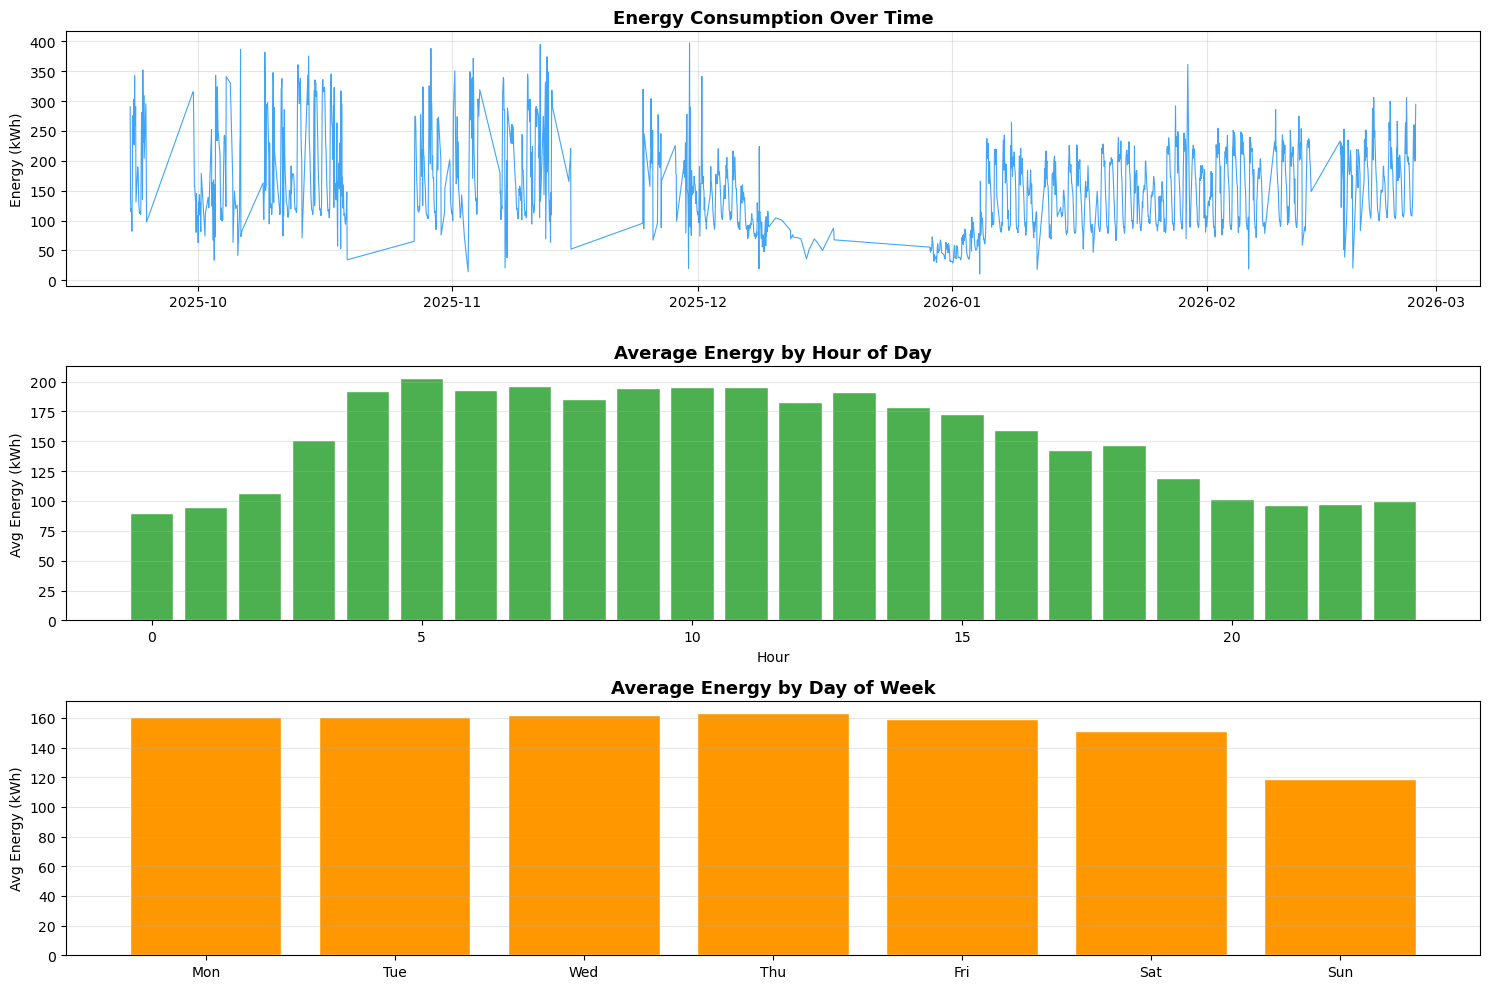

Saved: energy_time_patterns.png


In [10]:
# ── 9a. Energy Consumption Over Time ─────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(15, 10))

axes[0].plot(df.index, df[TARGET_COL], color="#2196F3", linewidth=0.8, alpha=0.85)
axes[0].set_title("Energy Consumption Over Time", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Energy (kWh)")
axes[0].grid(True, alpha=0.3)

# Hourly average profile
hourly_avg = df.groupby("hour")[TARGET_COL].mean()
axes[1].bar(hourly_avg.index, hourly_avg.values, color="#4CAF50", edgecolor="white")
axes[1].set_title("Average Energy by Hour of Day", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Avg Energy (kWh)")
axes[1].grid(True, alpha=0.3, axis="y")

# Day-of-week average
days = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
dow_avg = df.groupby("day_of_week")[TARGET_COL].mean()
axes[2].bar(dow_avg.index, dow_avg.values, color="#FF9800", edgecolor="white")
axes[2].set_title("Average Energy by Day of Week", fontsize=13, fontweight="bold")
axes[2].set_xticks(range(7))
axes[2].set_xticklabels(days)
axes[2].set_ylabel("Avg Energy (kWh)")
axes[2].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("../outputs/figures/energy_time_patterns.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: energy_time_patterns.png")


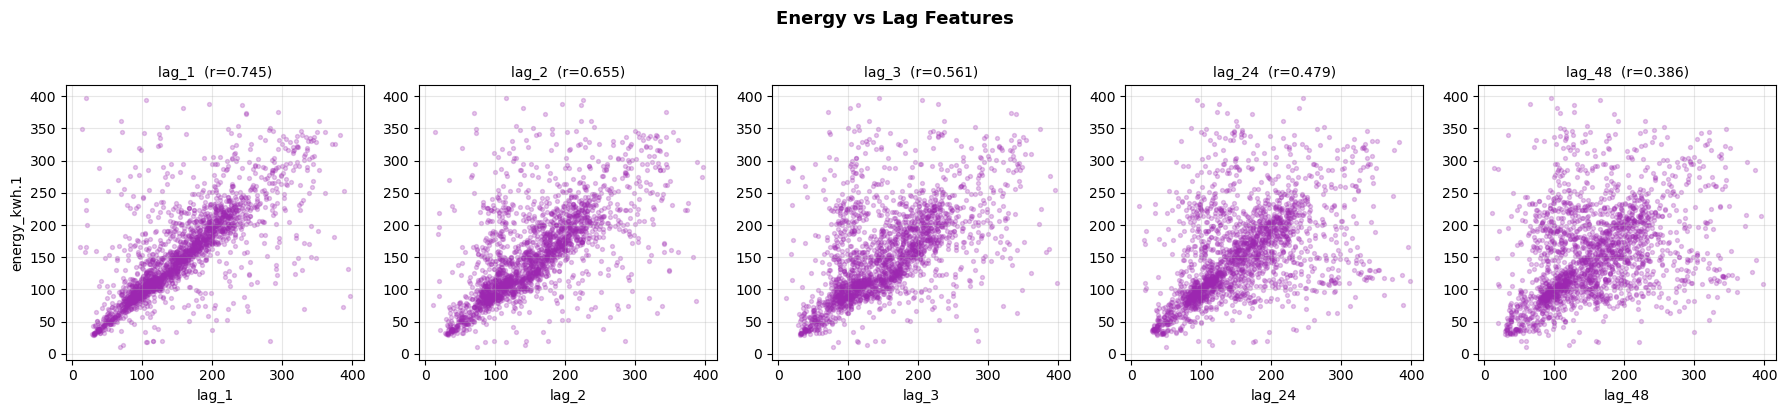

Saved: lag_scatter_plots.png


In [11]:
# ── 9b. Lag Scatter Plots ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, len(LAG_PERIODS), figsize=(18, 4))
for ax, lag in zip(axes, LAG_PERIODS):
    ax.scatter(df[f"lag_{lag}"], df[TARGET_COL],
               alpha=0.25, s=8, color="#9C27B0")
    corr = df[TARGET_COL].corr(df[f"lag_{lag}"])
    ax.set_title(f"lag_{lag}  (r={corr:.3f})", fontsize=10)
    ax.set_xlabel(f"lag_{lag}")
    ax.set_ylabel(TARGET_COL if lag == LAG_PERIODS[0] else "")
    ax.grid(True, alpha=0.3)

plt.suptitle("Energy vs Lag Features", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../outputs/figures/lag_scatter_plots.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: lag_scatter_plots.png")


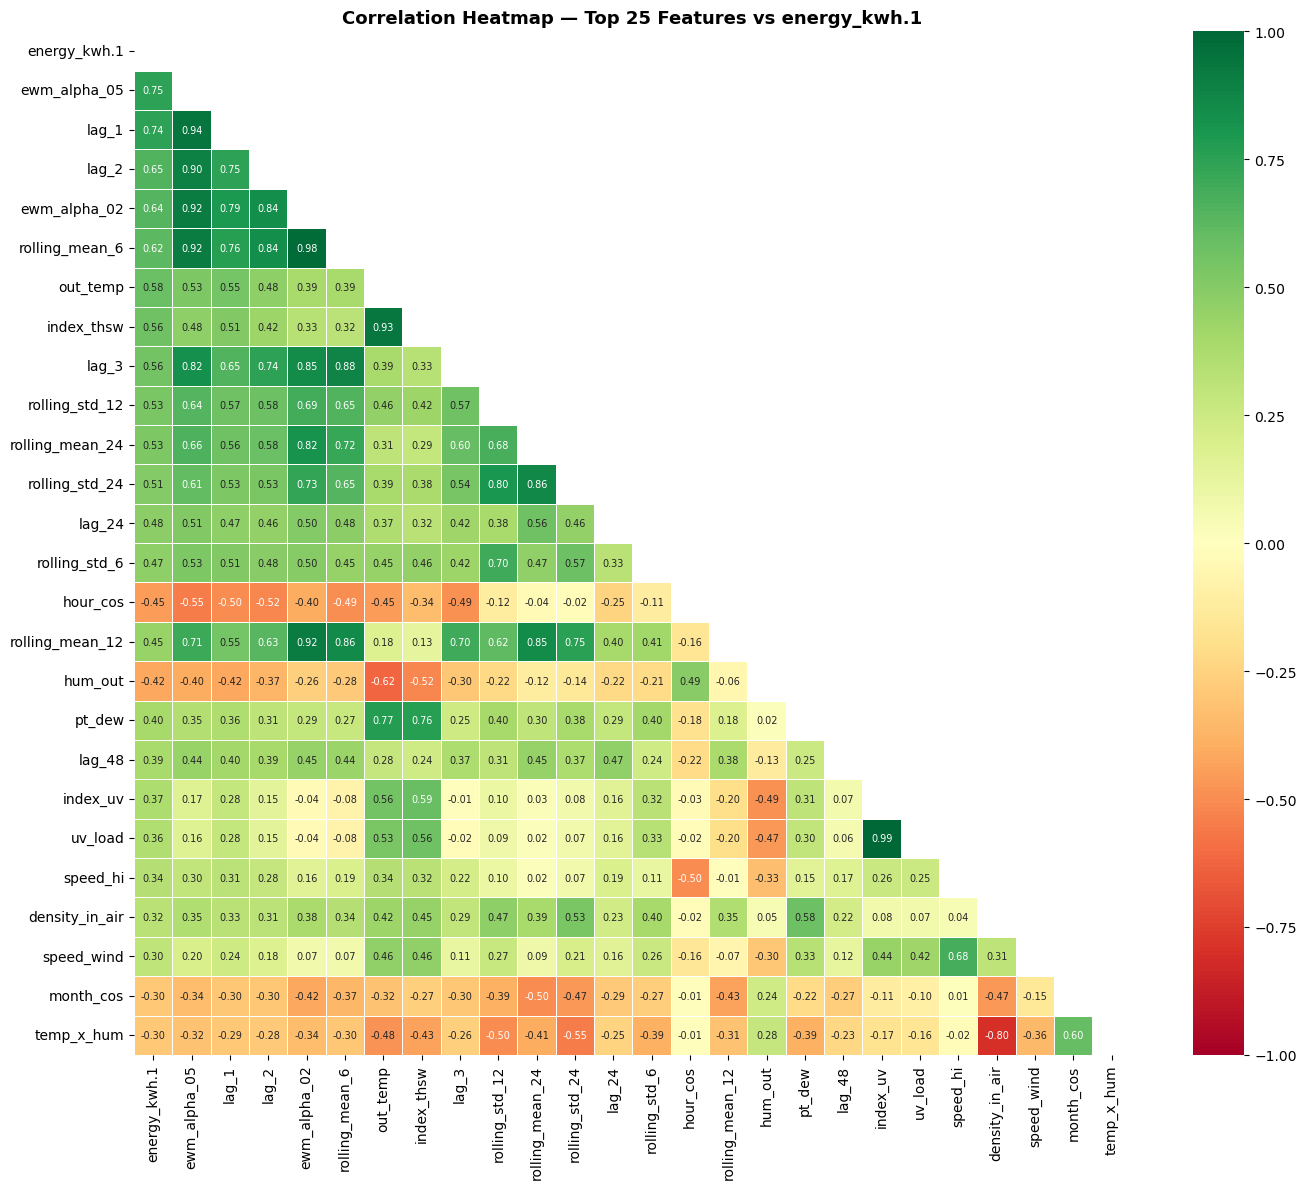

Saved: correlation_heatmap.png


In [12]:
# ── 9c. Correlation Heatmap (top-N most correlated features) ─────────────────
# Focus on features most correlated with the target for readability

TOP_N = 25
correlations = df.corr()[TARGET_COL].drop(TARGET_COL).abs().nlargest(TOP_N)
top_cols = [TARGET_COL] + correlations.index.tolist()

corr_matrix = df[top_cols].corr()

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # upper triangle mask
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f",
    cmap="RdYlGn", center=0, vmin=-1, vmax=1,
    linewidths=0.4, ax=ax,
    annot_kws={"size": 7}
)
ax.set_title(f"Correlation Heatmap — Top {TOP_N} Features vs {TARGET_COL}",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../outputs/figures/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: correlation_heatmap.png")


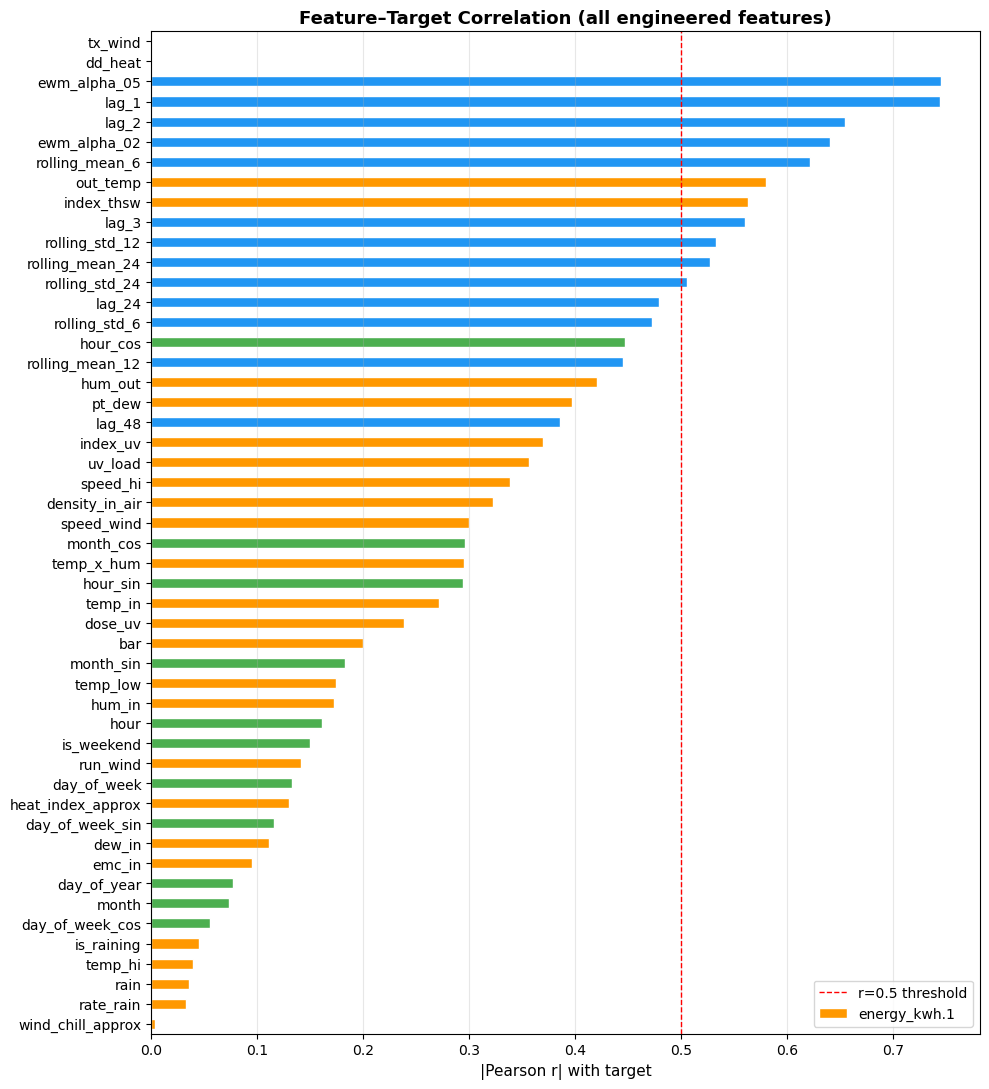

Saved: feature_importance_proxy.png


In [13]:
# ── 9d. Feature Importance Proxy (Pearson |r| with target) ───────────────────
corr_all = df.corr()[TARGET_COL].drop(TARGET_COL).abs().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, max(6, len(corr_all) * 0.22)))
colors = ["#2196F3" if "lag" in c or "rolling" in c or "ewm" in c
          else "#4CAF50" if any(t in c for t in ["hour","day","month","week","weekend"])
          else "#FF9800" for c in corr_all.index]
corr_all.plot(kind="barh", ax=ax, color=colors, edgecolor="white")
ax.set_xlabel("|Pearson r| with target", fontsize=11)
ax.set_title("Feature–Target Correlation (all engineered features)",
             fontsize=13, fontweight="bold")
ax.grid(True, alpha=0.3, axis="x")
ax.axvline(0.5, color="red", linestyle="--", linewidth=1, label="r=0.5 threshold")
ax.legend()
plt.tight_layout()
plt.savefig("../outputs/figures/feature_importance_proxy.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: feature_importance_proxy.png")


In [15]:
# ── 10. Save Final Dataset ────────────────────────────────────────────────────
df_out = df.reset_index()   # restore timestamp as a regular column
df_out.to_csv(OUTPUT_PATH, index=False)

print(f"✅ Saved  →  {OUTPUT_PATH}")
print(f"   Rows    : {df_out.shape[0]}")
print(f"   Columns : {df_out.shape[1]}")
print()
print("Column list:")
for i, col in enumerate(df_out.columns, 1):
    print(f"  {i:>3}. {col}")


✅ Saved  →  final_feature_engineered_dataset.csv
   Rows    : 2088
   Columns : 52

Column list:
    1. timestamp
    2. energy_kwh.1
    3. temp_hi
    4. bar
    5. dew_in
    6. temp_in
    7. pt_dew
    8. index_thsw
    9. index_uv
   10. hum_out
   11. dose_uv
   12. dd_heat
   13. temp_low
   14. density_in_air
   15. rain
   16. run_wind
   17. emc_in
   18. rate_rain
   19. out_temp
   20. speed_hi
   21. speed_wind
   22. tx_wind
   23. hum_in
   24. hour
   25. day_of_week
   26. month
   27. day_of_year
   28. is_weekend
   29. hour_sin
   30. hour_cos
   31. month_sin
   32. month_cos
   33. day_of_week_sin
   34. day_of_week_cos
   35. lag_1
   36. lag_2
   37. lag_3
   38. lag_24
   39. lag_48
   40. rolling_mean_6
   41. rolling_std_6
   42. rolling_mean_12
   43. rolling_std_12
   44. rolling_mean_24
   45. rolling_std_24
   46. ewm_alpha_02
   47. ewm_alpha_05
   48. temp_x_hum
   49. heat_index_approx
   50. wind_chill_approx
   51. is_raining
   52. uv_load
